# Stage 3: holdings and sectors

Findings 3 to 6 for **Wall Street in Charts**: where BlackRock, Vanguard and State Street invest, whether they choose or follow the market, energy, and how much of the US market they hold. All numbers come from `wallstreet/findings.py`, the same code behind the findings pages.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import pandas as pd
from IPython.display import SVG, display

from wallstreet import charts as C
from wallstreet import findings as F
from wallstreet.config import PROCESSED

pd.options.display.float_format = "{:,.1f}".format

## How the sector mapping did

Share of each firm's value mapped to a sector (the rest is mainly small or delisted companies). Then how each holding got its sector.

In [2]:
(F.mapped_share().describe().loc[["min", "mean"]] * 100)

firm,blackrock,state_street,vanguard
min,95.3,97.3,96.2
mean,96.7,98.2,97.5


In [3]:
m = pd.read_csv(PROCESSED / "sector_map.csv", dtype={"cusip": str})
m["method"].value_counts()

method
SIC code        2791
fund name        221
no match          64
hand-checked      49
Name: count, dtype: int64

## 3. Where do they invest?

Big Three sector mix (%) at the start and end, with the change in percentage points.

In [4]:
w = F.sector_weights("big_three") * 100
mix = pd.DataFrame({"2015": w.loc["2015-12-31"], "2025": w.loc["2025-12-31"]})
mix["Change"] = mix["2025"] - mix["2015"]
mix.sort_values("Change", ascending=False)

,2015,2025,Change
sector,,,
Technology,13.7,32.4,18.7
Consumer discretionary,8.4,9.5,1.1
Communication,7.8,8.7,0.9
Utilities,3.4,2.7,-0.7
Materials,3.7,2.6,-1.0
Financials,14.8,13.4,-1.4
Industrials,12.4,10.2,-2.2
Energy,6.0,3.0,-3.0
Real estate,6.3,3.0,-3.3


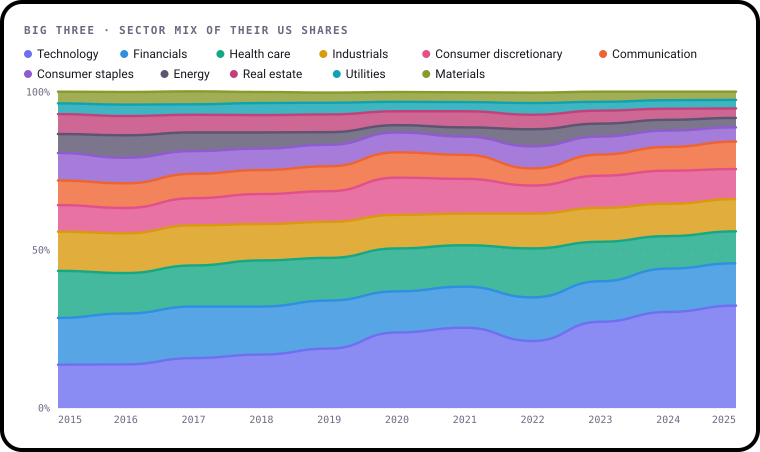

In [5]:
display(SVG(str(C.sector_area("light"))))

## 4. Choosing or following?

Distance from the market's sector mix (%): half the summed gaps across the 11 sectors. 0% is an exact copy.

In [6]:
d = F.distance_from_market() * 100
d.index = d.index.str[:4]
d.columns = [F.short_name(c) for c in d.columns]
d

,BlackRock,Vanguard,State Street
quarter_end,,,
2015,2.5,4.5,4.1
2016,2.5,4.2,4.1
2017,2.3,3.5,4.1
2018,2.5,3.1,4.0
2019,1.9,3.2,3.2
2020,1.8,2.8,3.0
2021,2.1,2.7,3.0
2022,2.2,2.6,4.2
2023,2.3,2.7,3.0


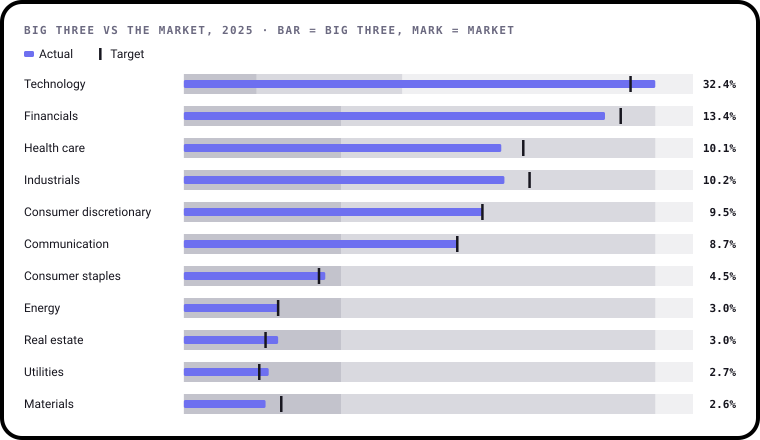

In [7]:
display(SVG(str(C.sector_bullets("light"))))

## 5. Energy

Oil, gas and coal as a share of each firm's US shares (%), and the market.

In [8]:
oil = F.energy_share("oil_gas_coal") * 100
oil[oil.index.str.endswith("12-31")]

firm,blackrock,market,state_street,vanguard
quarter_end,,,,
2015-12-31,5.4,5.1,6.4,5.5
2016-12-31,6.4,6.3,7.7,6.6
2017-12-31,5.3,5.2,6.4,5.5
2018-12-31,4.6,4.5,5.6,4.8
2019-12-31,3.5,3.7,4.4,3.9
2020-12-31,1.9,1.8,2.8,2.1
2021-12-31,2.4,2.4,3.6,2.7
2022-12-31,4.7,4.6,6.6,4.9
2023-12-31,3.5,3.6,5.0,3.8


In [9]:
pd.read_csv(PROCESSED / "clean_energy_matches.csv").groupby("company")[
    "value_usd"
].sum().sort_values(ascending=False).head(10) / 1e9

company
First Solar               213.8
Enphase Energy            195.8
SolarEdge Technologies     91.2
Sunrun                     74.2
Ormat Technologies         67.2
Plug Power                 61.2
Bloom Energy               56.7
Clearway Energy            43.6
Hannon Armstrong           33.4
NextEra Energy Partners    26.8
Name: value_usd, dtype: float64

## 6. The Big Three's share of the market

Each firm's company shares as a share of all US public company shares (%), at each year-end.

In [10]:
share = F.big_three_market_share() * 100
share = share[share.index.str.endswith("12-31")]
share["Combined"] = share.sum(axis=1)
share

firm,blackrock,vanguard,state_street,Combined
quarter_end,,,,
2015-12-31,5.6,5.8,3.5,14.9
2016-12-31,5.9,6.4,3.8,16.1
2017-12-31,6.1,6.9,3.7,16.7
2018-12-31,6.3,7.3,3.6,17.1
2019-12-31,6.5,7.6,3.8,17.8
2020-12-31,6.4,7.3,3.4,17.1
2021-12-31,6.4,7.4,3.5,17.3
2022-12-31,6.5,7.8,3.6,17.9
2023-12-31,6.6,7.9,3.6,18.1


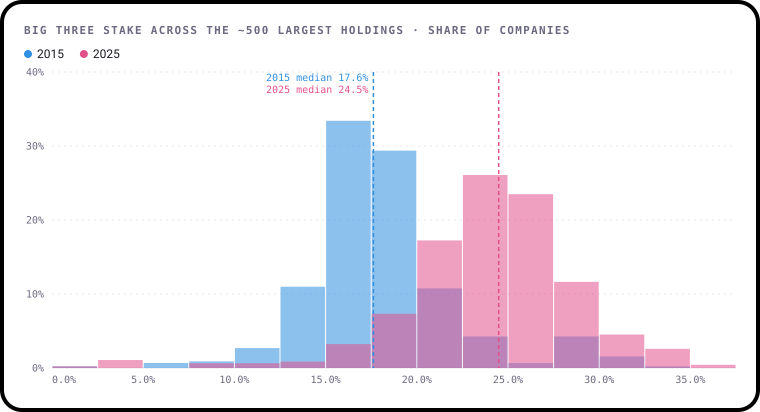

In [11]:
display(SVG(str(C.stake_histogram("light"))))

## The numbers the text quotes

In [12]:
pd.Series(F.headline_numbers_holdings()).to_frame("value")

,value
tech_share_2015,0.1
tech_share_2025,0.3
market_tech_share_2025,0.3
energy_share_2015,0.1
energy_share_2025,0.0
biggest_fallers,"health care, consumer staples, real estate and..."
sectors_grew,3
top_sector_2025,Technology
top_sector_2025_share,0.3
blackrock_distance_2015,0.0
